# Heartsteps Matrix Completion using Nearest Neighbor Strategies

## Motivation

Within many real-world applications, there is an interest in measuring reaction to stimuli over time. For example, in a medical trial for a new drug, participants might receive dosages at various times over the trial period. This yields a unique structure of data, where patients (units) receive drug dosages (treatments) at certain times (decision points) while being monitored in between dosages for changes in health condition (outcomes). 

Consider a more general case: there are $N$ units who undergo $T$ potential treatment periods. At treatment period $t$, a unit $i$ receives treatment if $A_{i, t} = 1$ and does not if $A_{i, t} = 0$. Suppose for each combination of unit $i$ and treatment period $T$, there are $n$ measurements of the characteristics of unit $i$ at this treatment period. We denote these measurements as $X_k(i, t) \in \mathbb{R}^d$ for $k \in [n]$. Each $X_k(i, t)$ is sampled from a unit-treatment period specific distribution $\mu_{i, t}$. To estimate the effect of the treatment strategy across $T$ periods at a unit-treatment level of specificity, we must consider the counterfactuals: the measurements $X_k(i, t)$ such that the treatment $A_{i, t}$ is the opposite of what was observed.

To be continued...

## Structure

We make the assumption that the data is stored in a format similar to the Heartsteps dataset shown below. Each row represents a user and a segment of time (in the Heartsteps case, every 5 minutes from 9:05am-9:00pm). Each row indicates the outcome of interest and whether or not the treatment was applied during that measurement time. 

`transfom_dnn` takes in data formatted like this and transforms it into usable arrays that match the problem description above. More specifically, it creates 2 matrices, $A$ and $M$ both of size $N$ x $T$. As above, $A$ is the treatment matrix, where $A_{ij} = 1$ when unit $i$ received the treatment at treatment period $j$ and $A_{ij} = 0$ otherwise. Each entry of $M$ is an array of length $n$ that contains the measurements of the outcome of interest. 

## Data

In [117]:
import numpy as np
import pandas as pd
from itertools import chain
import itertools
import datetime
from matplotlib.pyplot import matshow
import matplotlib.pyplot as plt

In [69]:
# read in Heartsteps dataset
df_hs = pd.read_csv("data_use.csv")
df_hs

,user.index,date,time,5min_datetime,steps,rolling_sum,rt,sugg.decision.5min,send.sedentary,availability
0,1,7/22/2015,9:05:00,NaN,0,0,1,NaN,0,1
1,1,7/22/2015,9:10:00,NaN,0,0,1,NaN,0,1
2,1,7/22/2015,9:15:00,NaN,0,0,1,NaN,0,1
3,1,7/22/2015,9:20:00,NaN,0,0,1,NaN,0,1
4,1,7/22/2015,9:25:00,NaN,0,0,1,NaN,0,1
...,...,...,...,...,...,...,...,...,...,...
228235,37,1/26/2016,20:40:00,NaN,0,0,1,NaN,0,1
228236,37,1/26/2016,20:45:00,NaN,0,0,1,NaN,0,1
228237,37,1/26/2016,20:50:00,NaN,0,0,1,NaN,0,1
228238,37,1/26/2016,20:55:00,NaN,0,0,1,NaN,0,1


In [70]:
# format 'date' as datetime objects
#df_hs['date'] = pd.to_datetime(df_hs['date'])
df_hs['date_time'] = df_hs['date'] + ' ' + df_hs['time']
df_hs['date_time'] = pd.to_datetime(df_hs['date_time'])
df_hs['treatment'] = df_hs['send.sedentary']

C:\Users\Caleb\AppData\Local\Temp\ipykernel_26608\98446096.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_time_ind["date"] = pd.to_datetime(df_time_ind["date"])


<Axes: xlabel='date'>

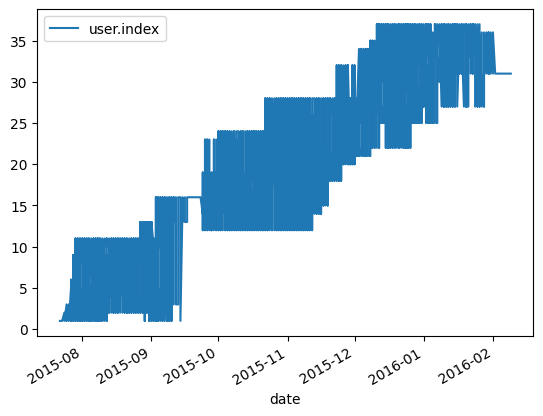

In [71]:
# checking unit overlap for better consistency
df_time_ind = df_hs[["user.index", "date"]]
df_time_ind["date"] = pd.to_datetime(df_time_ind["date"])

df_time_ind.plot("date","user.index")
# range df
#max(df_time_ind[df_time_ind["user.index"] == 1]["date"])


## Define `transform_dnn`

### First pass: assuming all trials start at the same time

In [72]:
def transform_dnn(df, day_partitions = 4, day_measure = 144, units = 37):
    """
    Transfom df into shape suitable for DNN use case.

    Parameters
    ----------
    df : pandas DataFrame
         a matrix of size Z x 10 (with a set of properties to be defined)
         ...
    day_partitions : int
        The number of partitions to split an individual day into. The 
        default value is 4. Maximally, the value of day_partitions is 
        day_measure.
    day_measure : int
        The number of measurements per "day" in df. The default is 144,
        which aligns with the measurements per day in the HeartSteps dataset.
    units : int
        The number of units in df. Default is 37 (in line with the HeartSteps dataset)        
    Returns
    ----------
    tuple (M, A)
    where M is a units x (day_partitions * D) x (day_measure / day_partitions) np array 
    that contains the outcome vectors of interest and A is a np array shape units x (day_partitions * D)
    that indicates in which unit/time combination a treatment was observed.
    D is the maximum length of days observed among all unit trials.
    """
    # first, find the maximum trial length in days
    # units are 1-indexed
    max_days = 0
    num_days = []
    for i in range(1, units + 1):
        len_i = len(df[df['user.index'] == i]) // day_measure
        num_days.append(len_i)
        if len_i > max_days:
            max_days = len_i
    # init M and A
    M = np.zeros((units, day_partitions * max_days, day_measure // day_partitions))
    A = np.zeros((units, day_partitions * max_days))
    
    for i in range(units):
        # note: i is used to index into M and A.
        # unit_ind is used to retrieve unit specific values from df
        unit_ind = i + 1
        
        # slice by unit
        df_unit = df.loc[df["user.index"] == unit_ind]
        
        # pad first to max trial length to maintain partition size across units
        trial_steps = df_unit["steps"].to_numpy()
        trial_trt = df_unit["treatment"].to_numpy()
        if num_days[i] < max_days:
            # pad with 0s, step values are masked by trt
            pad = np.empty((max_days - num_days[i]) * day_measure)
            pad.fill(np.nan)
            trial_steps = np.append(trial_steps, pad)
            pad_trt = np.zeros((max_days - num_days[i]) * day_measure)
            trial_trt = np.append(trial_trt, pad_trt)
            
        # first split into days, then into partitions
        lst_days = np.split(trial_steps, max_days)
        parts = np.array([np.split(x, day_partitions) for x in lst_days])
         
        # Shape of parts is max_days x day_partitions x (day_measure // day_partitions)
        # Flatten along d dimension to achieve (day_partitions * max_days) x (day_measure // day_partitions) shape
        unit_parts = parts.reshape((max_days * day_partitions, day_measure // day_partitions))
        
        # Repeat for treatment col. 
        lst_days_trt = np.split(trial_trt, max_days)
        parts_trt = np.array([np.split(x, day_partitions) for x in lst_days_trt])
        unit_trt = parts_trt.reshape((max_days * day_partitions, day_measure // day_partitions))
        
        # if any of the trt values within the partition is 1, set the value in the final array to 1
        unit_trt_agg = unit_trt.any(axis = 1).astype(int)
        
        M[i] = unit_parts
        A[i] = unit_trt_agg
        A = A.astype('int32')
    return M, A
    

### Second pass: maintaining original time structure

One key observation from our preliminary data analysis (see Fig. 1) is that units start their trials at different times and have varying trial lengths, creating a "chunk"-like structure. To preserve time-specific effects (such as seasonal changes or disparities in weekday vs. weekend behavior), we add to our definition of `transform_dnn`. We wish to maintain the same chronological order as the input data. Thus, we dynamically pad each user's trial period on both ends to stretch from the minimum trial start date to the maximum trial start date. This padding will create additional missingness in the off-diagonals, which we will investigate later. Additionally, we add `np.nan` entries for days within the trial period that do not have observations, which improves upon the previous approach of ignoring such gaps. 

In [73]:
def pad_dates(df, freq = '5T', range_begin = '09:05:00', range_end = '21:00:00'):
    """
    Extend trial dates in df['date'] so that each unit has max(df['date']) - min(df['date'])
    days in a trial. Observations that are synthetically created in this process are imputed with
    np.nan
    
    Parameters:
    ----------
    df : a Dataframe with columns `date`, `treatment`, `steps`, and `user.index`
    
    Returns:
    ----------
    df_extend : the extended Dataframe described above
    """
    start_day = min(df['date_time'])
    end_day = max(df['date_time'])
    df = df.set_index('date_time')

    
    def reind_id(df_u):
        rng = pd.date_range(start_day, end_day, freq = freq)
        if range_begin is not None:
            rng = rng[rng.indexer_between_time(range_begin, range_end)]
        df_reind = df_u.reindex(rng)
        df_reind['user.index'] = df_reind['user.index'].ffill().bfill()
        return df_reind
        
    
    df_final = df.groupby('user.index', group_keys = False).apply(lambda df_u:reind_id(df_u))
    df_final = df_final.reset_index(names = "date_time")
    
    df_final['user.index'] = df_final['user.index'].astype("int32")
    
    return df_final[['user.index','treatment', 'steps']]
    
        
def transform_dnn_pad(df, day_partitions = 4, day_measure = 144, units = 37, freq ="5T", 
                      range_begin = '09:05:00', range_end ='21:00:00'):
    """
    Transfom df into shape suitable for DNN use case.

    Parameters
    ----------
    df : pandas DataFrame
         a matrix of size Z x 10 (with a set of properties to be defined)
         ...
    day_partitions : int
        The number of partitions to split an individual day into. The 
        default value is 4. Maximally, the value of day_partitions is 
        day_measure.
    day_measure : int
        The number of measurements per "day" in df. The default is 144,
        which aligns with the measurements per day in the HeartSteps dataset.
    units : int
        The number of units in df. Default is 37 (in line with the HeartSteps dataset)        
    Returns
    ----------
    tuple (M, A)
    where M is a units x (day_partitions * D) x (day_measure / day_partitions) np array 
    that contains the outcome vectors of interest and A is a np array shape units x (day_partitions * D)
    that indicates in which unit/time combination a treatment was observed.
    D is the maximum length of days observed among all unit trials.
    """
    df = pad_dates(df, freq, range_begin, range_end)
    
    # all days now have the same length
    max_days = len(df[df['user.index'] == 1]) // day_measure
    # init M and A
    M = np.zeros((units, day_partitions * max_days, day_measure // day_partitions))
    A = np.zeros((units, day_partitions * max_days))
    
    
    for i in range(units):
        # note: i is used to index into M and A.
        # unit_ind is used to retrieve unit specific values from df
        unit_ind = i + 1
        
        # slice by unit
        df_unit = df.loc[df["user.index"] == unit_ind]
        
        trial_steps = df_unit["steps"].to_numpy()
        trial_trt = df_unit["treatment"].to_numpy()
            
        # first split into days, then into partitions
        lst_days = np.array_split(trial_steps, max_days)
        parts = np.array([np.array_split(x, day_partitions) for x in lst_days], dtype = object)
        #print(parts)
         
        # Shape of parts is max_days x day_partitions x (day_measure // day_partitions)
        # Flatten along d dimension to achieve (day_partitions * max_days) x (day_measure // day_partitions) shape
        unit_parts = parts.reshape((max_days * day_partitions, day_measure // day_partitions))
        
        # Repeat for treatment col. 
        lst_days_trt = np.array_split(trial_trt, max_days)
        parts_trt = np.array([np.array_split(x, day_partitions) for x in lst_days_trt])
        unit_trt = parts_trt.reshape((max_days * day_partitions, day_measure // day_partitions))
        
        # if any of the trt values within the partition is 1, set the value in the final array to 1
        unit_trt_agg = np.nan_to_num(unit_trt, nan = 0).any(axis = 1).astype(int)
        
        M[i] = unit_parts
        A[i] = unit_trt_agg
        A = A.astype('int32')
    return M, A
    

## Testing `transform_dnn` with simulated symmetrical data

We create a small test dataset as a proof of concept of the above data transformation. This data set will have 3 units over a time span of 4 days, with 12 measurements a day. We partition each day into 3 segments (4 measurements per partition). The treatment is randomly applied across each day and time span. This is a simpler example than the actual use case, as the number of days within the trial is consistent for all users. See the section below for a more complex example.

In [74]:
# create test set

# user inds
u1 = np.repeat(1, 12 * 4)
u2 = np.repeat(2, 12 * 4)
u3 = np.repeat(3, 12 * 4)
user_index = np.concatenate((u1, u2, u3))

# step measurements (for simplicity, between 1 and 10)
rng = np.random.default_rng()
u1_steps = rng.integers(low=1, high=10, size=12 * 4)
u2_steps = rng.integers(low=1, high=10, size=12 * 4)
u3_steps = rng.integers(low=0, high=10, size=12 * 4)
steps = np.concatenate((u1_steps, u2_steps, u3_steps))
 
# treatment measurements
# in practice, it seems much more likely to see no treatment rather than a treatment
u1_trt = np.random.choice([0, 1], 12 * 4, p=[0.8, 0.2])
u2_trt = np.random.choice([0, 1], 12 * 4, p=[0.8, 0.2])
u3_trt = np.random.choice([0, 1], 12 * 4, p=[0.8, 0.2])
trt = np.concatenate((u1_trt, u2_trt, u3_trt))

# time of measurements
single = pd.Series(pd.date_range("2024-06-14", "2024-06-18", inclusive = "left", freq = '2h'))
# create final dataframe
final_np = np.stack((user_index, steps, trt), axis = 1)
df_symtest = pd.DataFrame(final_np, columns = ["user.index", "steps", "treatment"]) 
df_symtest["date_time"] = pd.concat([single, single, single]).reset_index(drop = "True")

df_symtest

,user.index,steps,treatment,date_time
0,1,5,1,2024-06-14 00:00:00
1,1,6,0,2024-06-14 02:00:00
2,1,8,0,2024-06-14 04:00:00
3,1,4,0,2024-06-14 06:00:00
4,1,4,0,2024-06-14 08:00:00
...,...,...,...,...
139,3,3,1,2024-06-17 14:00:00
140,3,6,0,2024-06-17 16:00:00
141,3,0,0,2024-06-17 18:00:00
142,3,1,0,2024-06-17 20:00:00


Now that we have created our test set, we can use `transform_dnn_pad` to demonstrate the desired transformation properties.

In [75]:
M, A = transform_dnn_pad(df_symtest, day_partitions = 3, day_measure = 12, units = 3, freq = "2h", range_begin = None)

In [76]:
M

array([[[5., 6., 8., 4.],
        [4., 3., 1., 1.],
        [3., 4., 9., 2.],
        [3., 7., 4., 1.],
        [7., 1., 7., 3.],
        [1., 2., 9., 7.],
        [1., 1., 5., 9.],
        [2., 9., 5., 8.],
        [3., 9., 4., 9.],
        [8., 8., 1., 3.],
        [5., 6., 4., 5.],
        [4., 3., 2., 6.]],

       [[8., 3., 5., 9.],
        [1., 6., 4., 2.],
        [3., 1., 7., 4.],
        [8., 4., 3., 3.],
        [7., 4., 4., 9.],
        [1., 1., 9., 1.],
        [8., 8., 1., 3.],
        [2., 7., 7., 9.],
        [2., 7., 3., 1.],
        [2., 3., 4., 3.],
        [2., 3., 3., 9.],
        [3., 6., 3., 5.]],

       [[8., 8., 5., 1.],
        [5., 2., 7., 0.],
        [5., 6., 7., 5.],
        [3., 7., 3., 6.],
        [3., 1., 1., 0.],
        [8., 1., 6., 9.],
        [6., 6., 1., 7.],
        [0., 6., 1., 5.],
        [0., 8., 9., 6.],
        [4., 5., 1., 3.],
        [2., 5., 2., 3.],
        [6., 0., 1., 9.]]])

In [77]:
A

array([[1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1],
       [0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1],
       [0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0]])

## Testing `transform_dnn` on simulated asymmetrical data

Next, we test the function on a dataset with asymmetrical trial periods. As before, we will have 3 units, but this time, one of the units has a longer 6 day trial period. The remaining units have a 4 day trial period. There are still 12 measurements a day, and each day has 3 segments.

In [78]:
# create test set
# user inds, u1 has 6 day trial period
u1 = np.repeat(1, 12 * 6)
u2 = np.repeat(2, 12 * 4)
u3 = np.repeat(3, 12 * 4)
user_index = np.concatenate((u1, u2, u3))

# step measurements (for simplicity, between 1 and 10)
rng = np.random.default_rng()
u1_steps = rng.integers(low=1, high=10, size=12 * 6)
u2_steps = rng.integers(low=1, high=10, size=12 * 4)
u3_steps = rng.integers(low=0, high=10, size=12 * 4)
steps = np.concatenate((u1_steps, u2_steps, u3_steps))
 
# treatment measurements
# in practice, it seems much more likely to see no treatment rather than a treatment
u1_trt = np.random.choice([0, 1], 12 * 6, p=[0.8, 0.2])
u2_trt = np.random.choice([0, 1], 12 * 4, p=[0.8, 0.2])
u3_trt = np.random.choice([0, 1], 12 * 4, p=[0.8, 0.2])
trt = np.concatenate((u1_trt, u2_trt, u3_trt))

single = pd.Series(pd.date_range("2024-06-14", "2024-06-18", inclusive = "left", freq = '2h'))
longer = pd.Series(pd.date_range("2024-06-14", "2024-06-20", inclusive = "left", freq = '2h'))
# create final dataframe
final_np = np.stack((user_index, steps, trt), axis = 1)
df_asymtest = pd.DataFrame(final_np, columns = ["user.index", "steps", "treatment"])
df_asymtest["date_time"] = pd.concat([longer, single, single]).reset_index(drop = "True")
df_asymtest

,user.index,steps,treatment,date_time
0,1,4,0,2024-06-14 00:00:00
1,1,6,0,2024-06-14 02:00:00
2,1,3,0,2024-06-14 04:00:00
3,1,9,0,2024-06-14 06:00:00
4,1,6,1,2024-06-14 08:00:00
...,...,...,...,...
163,3,1,0,2024-06-17 14:00:00
164,3,6,0,2024-06-17 16:00:00
165,3,3,0,2024-06-17 18:00:00
166,3,1,0,2024-06-17 20:00:00


In [79]:
M_a, A_a = transform_dnn_pad(df_asymtest, day_partitions = 3, day_measure = 12, units = 3, freq = "2h", range_begin = None)

In [80]:
M_a

array([[[ 4.,  6.,  3.,  9.],
        [ 6.,  2.,  8.,  1.],
        [ 9.,  1.,  8.,  2.],
        [ 2.,  2.,  8.,  6.],
        [ 1.,  4.,  4.,  5.],
        [ 2.,  3.,  1.,  6.],
        [ 8.,  7.,  9.,  1.],
        [ 9.,  4.,  7.,  8.],
        [ 8.,  2.,  1.,  2.],
        [ 5.,  3.,  2.,  9.],
        [ 5.,  1.,  5.,  8.],
        [ 4.,  7.,  3.,  7.],
        [ 7.,  4.,  6.,  3.],
        [ 6.,  6.,  9.,  4.],
        [ 2.,  8.,  8.,  7.],
        [ 1.,  6.,  9.,  2.],
        [ 2.,  3.,  2.,  7.],
        [ 9.,  8.,  9.,  4.]],

       [[ 8.,  6.,  4.,  3.],
        [ 7.,  4.,  1.,  8.],
        [ 9.,  4.,  5.,  7.],
        [ 2.,  3.,  1.,  8.],
        [ 9.,  5.,  3.,  7.],
        [ 8.,  5.,  8.,  9.],
        [ 3.,  2.,  4.,  1.],
        [ 2.,  5.,  2.,  2.],
        [ 4.,  4.,  4.,  3.],
        [ 5.,  8.,  4.,  5.],
        [ 5.,  9.,  1.,  3.],
        [ 6.,  6.,  7.,  5.],
        [nan, nan, nan, nan],
        [nan, nan, nan, nan],
        [nan, nan, nan, nan],
        

In [81]:
A_a

array([[0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1],
       [1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0],
       [1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0]])

## Test `transform_dnn` on HeartSteps dataset

Finally, we test `transform_dnn` on its primary use case, the HeartSteps dataset. We use `send.sedentary` as the "treatment" indicator. For testing of the `transform_dnn_pad` function, see above.

In [82]:
df_hs["treatment"] = df_hs["send.sedentary"]

We can see that there are 37 units. Time statistics run from 9:05 to 21:00 at 5 minute intervals, yielding 12 observations per hour for 12 hours. This means that there are 144 measurements per day. We will demonstrate by partitioning the data into 4 sections per day (i.e. each section has 36 measurements). 

In [83]:
# note/question: it seems that 4 measurements may be too granular to find enough neighbors
M_hs, A_hs = transform_dnn(df_hs, day_partitions = 4, day_measure = 144, units = 37)

In [84]:
with np.printoptions(threshold=np.inf):
    print(M_hs[0, :, :])

[[  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
    0.   0.   0.   0.   0.   0.   0.   0.  67. 115.  60.   0.  61.   0.
  169.   0.   0. 524. 324.   0.  26.   0.]
 [  0.   0.   0.   0.   0.   0.   0.   0. 212. 396. 457. 246.   0. 102.
    0.   0.   0.   0.   0.  38.   0.   0.  64. 102.   0. 123.  74. 221.
    0.   0. 260. 154.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.  62.   0.  60. 170.  28. 326.  25.
    0.   0.   0.   0.   0.  92.  21.  57.   0.  25. 135.  22.   0.   0.
   72.  32.  70.  70. 108.  68.  25.   0.]
 [ 83.  31.  18.   0.   0.   0.  93.  33.  56. 135. 365. 580. 584. 584.
  576. 558. 523.  88. 229.   0.   0.   0.   0. 140.   0.   0.   0.  92.
   27. 227.   0.   0.   0. 156. 122.  89.]
 [590. 587. 279.   4. 113. 131.   0.   0.   0.   0.   0.   0. 136. 101.
   12.  89. 129.  60. 148.  81.  65.   0.  44.   0.  88. 196.  50.  54.
   89. 210.  52. 194. 143. 121. 294. 126.]
 [206. 147. 277. 350. 119. 147. 157.   0. 183. 349. 204.   0. 173

### Testing `transform_dnn_pad`

Finally, we test the adjusted function `transform_dnn_pad` to see if it maintains the desired properties.

In [85]:
M_hs, A_hs = transform_dnn_pad(df_hs)

In [86]:
A_hs

array([[0, 0, 1, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

We can see that the transformed data now obeys the original chronological ordering. The below image also gives a sense of the patterns of missingness that we will attempt to handle in the following sections.

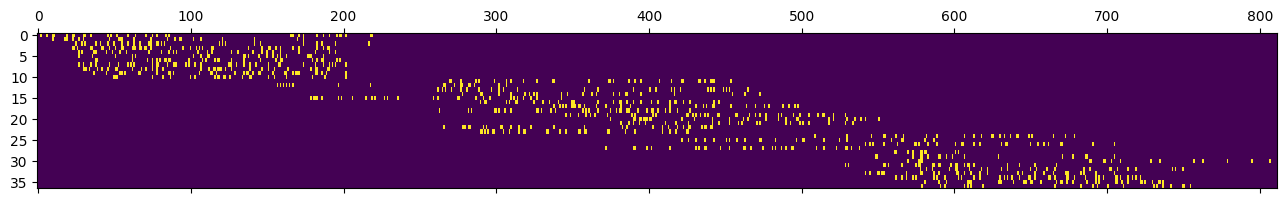

In [87]:
matshow(A_hs, aspect = 'auto')

### NN feasibility of mean-flattened Heartsteps data

First, we want to get a sense of how many observed (treated) values we have, since it seems that the treatment is applied relatively infrequently. If we have too few of these observed values, it could limit the number of potential neighbors that we could use to impute value.

In [88]:
nz_e = len(np.nonzero(A_hs)[0])
print("There are " + str(nz_e) + " nonzero entries")
print("The ratio of nonzero to zero entries is " + str(nz_e / (A_hs.size)))  

There are 1001 nonzero entries
The ratio of nonzero to zero entries is 0.03331780055917987


A $\sim \frac{1}{30}$ of zero to nonzero entries is pretty low. Let's see how it might affect average potential neighborhood size. To do this, we examine each zero entry in the masking matrix and consider how many possible neighbors could be used to impute it. Then we take the average number of possible neighbors.

In [89]:
total_pos_nn = 0
obs = np.nonzero(A_hs == 0)
for i in range(len(obs[0])): 
    total_pos_nn += np.sum(A_hs[obs[0][i], :])
print(total_pos_nn / len(obs[0]))
    

27.004958165478772


This might be slightly concerning, as the possible number of neighbors that could be used to impute this value is already quite small with no guarentees about closeness. 

## Li 2019 Nearest Neighbors Implementation

We implement the user-user nearest neighbors algorithm as defined in Nearest Neighbors for Matrix Estimation Interpreted as Blind Regression for Latent Variable Model (Li et al. 2019). More specifically, we construct Algorithm 2, which can be found in Section III [here](https://arxiv.org/abs/1705.04867).

First, to align the NN implementation with the data format considered above, we define a function to collapse the partitioned measurements dimension (3rd dim) to its mean.

In [90]:
def mean_collapse(A, d = 2):
    """
    Returns A (3d array) with dth dimension collapsed as mean
    """
    return np.nanmean(A, axis = d)

Next, we construct the necessary functions as defined in Li 2019.

In [91]:
def dissim_col(O, M, u, v):
    """
    Returns the col dissimilarity between cols u and v
    in O
    
    Parameters
    ----------
    O : a matrix of size a x b
    M : a masking matrix of size a x b that
        dictates which entries of O are known 
    u : the index of a cols in O
    v : the index of a col in O

    Returns
    ----------
    d_col : the col dissimilarity between u and v (float)
    """
    obv_col_mask = M[:, u] * M[:, v]
    overlap = np.nansum(obv_col_mask)
    if not overlap:
        return float('inf')    
    sd = (O[:, u] - O[:, v])**2 * obv_col_mask 
    msd = (1 / overlap) * np.nansum(sd)
    return msd
    
    
def dissim_row(O, M, u, v):
    """
    Returns the row dissimilarity between rows u and v
    in O
    
    Parameters
    ----------
    O : a matrix of size a x b
    M : a masking matrix of size a x b that
        dictates which entries of O are known 
    u : the index of a row in O
    v : the index of a row in O

    Returns
    ----------
    d_row : the row dissimilarity between u and v (float)
    """
    obv_col_mask = M[u] * M[v]
    overlap = np.nansum(obv_col_mask)
    if not overlap:
        return float('inf')    
    sd = (O[u] - O[v])**2 * obv_col_mask 
    msd = (1 / overlap) * np.nansum(sd)
    return msd

def nearest_neighbors(O_1, u, M, eta, variation = "user-user"):
    """
    Returns the B neighborbood around u using rows/cols in O_1 within
    radius eta. 
    
    Parameters
    ----------
    O_1 : a matrix of size c x d
    u : index of row/col u in O_1 and M
    M : a masking matrix of size c x d that
        dictates which entries of O_1 are known 
    eta : radius of B neighborhood
    variation : "user-user", "item-item" dictates which variation
                of nearest neighbors is being used. Default: "user-user"
    
    Returns
    ----------
    B : neighborhood (indicies of most similar rows/cols)
        with radius eta
    """
    if variation == "item-item":
        dissims = np.array([dissim_col(O_1, M, u, v) for v in range(len(O_1[0]))])
    else:
        dissims = np.array([dissim_row(O_1, M, u, v) for v in range(len(O_1))])        
    # remove u from neighbors
    #dissims = np.delete(dissims, u, 1)
    B = np.nonzero(dissims <= eta)
    return B
    
    
    
def estimate_li_nn(Z, M, eta):
    """
    Returns A_hat, the estimate of partially unobvserved
    matrix A using Nearest Neighbors imputation
    
    Parameters
    ----------
    Z : an array of size m x n x q
    M : a masking matrix of size m x n that
        dictates which entries of Z are known 
    eta : radius of B neighborhood
    
    Returns
    ----------
    A_hat : the estimate of partially unobvserved matrix A
    """
    Z = mean_collapse(Z, d = 2)
    m, n = Z.shape
    A_hat = np.zeros((m, n))
    for u in range(m):
        for v in range(n):
            # sample splitting: artificially mask out values in the column of the
            # cell we are interested in
            O_1 = Z.copy()
            O_2 = Z[:, j]
            M_v = M.copy()
            M_v[:,j] = 0
            u_neighbors = nearest_neighbors(O_1, u, M_v, eta)
            # only select observed neighbors
            mask = M[u_neighbors, v]
            pos_nn = Z[u_neighbors, v]
            masked_nn = pos_nn[mask == 1]
            if not len(masked_nn):
                A_hat[u, v] = 0
            else:
                A_hat[u, v] = np.nanmean(masked_nn)
    return A_hat

def estimate_li_nn_inds(Z, M, eta, v_inds):
    """
    Returns A_hat, the estimate of partially unobvserved
    matrix A using Nearest Neighbors imputation, with only indices specified
    by v_inds estimated (user-user variation)
    
    Parameters
    ----------
    Z : an array of size m x n x q
    M : a masking matrix of size m x n that
        dictates which entries of Z are known 
    eta : radius of B neighborhood
    v_inds : indices to estimate, tuple of (x_coords, y_coords)
    
    Returns
    ----------
    A_hat : the estimate of values in partially unobserved matrix A specified by v_inds
    """
    row_coords, col_coords = v_inds
    Z = mean_collapse(Z, d = 2)
    m, n = Z.shape
    A_hat = np.zeros((m, n))
    for i in range(len(row_coords)):
        u = row_coords[i]
        j = col_coords[i]
        # sample splitting: artificially mask out values in the column of the
        # cell we are interested in
        O_1 = Z.copy()
        O_2 = Z[:, j]
        M_j = M.copy()
        M_j[:,j] = 0
        u_neighbors = nearest_neighbors(O_1, u, M_j, eta)
        mask = M[u_neighbors, j]
        pos_nn = Z[u_neighbors, j]
        masked_nn = pos_nn[mask == 1]
        if not len(masked_nn):
            A_hat[u, j] = 0
        else:
            A_hat[u, j] = np.nanmean(masked_nn)
    return A_hat
        
def estimate_li_nn_inds_cols(Z, M, eta, v_inds):
    """
    Returns A_hat, the estimate of partially unobvserved
    matrix A using Nearest Neighbors imputation, with only indices specified
    by v_inds estimated (item-item variation)
    
    Parameters
    ----------
    Z : an array of size m x n x q
    M : a masking matrix of size m x n that
        dictates which entries of Z are known 
    eta : radius of B neighborhood
    v_inds : indices to estimate, tuple of (x_coords, y_coords)
    
    Returns
    ----------
    A_hat : the estimate of values in partially unobserved matrix A specified by v_inds
    """
    row_coords, col_coords = v_inds
    Z = mean_collapse(Z, d = 2)
    m, n = Z.shape
    A_hat = np.zeros((m, n))
    for i in range(len(row_coords)):
        u = row_coords[i]
        j = col_coords[i]
#         O_1  = np.delete(Z, u, axis = 0)
#         O_2 = Z[u, :]
#         M_j = np.delete(M, u, axis = 0)
        # sample splitting: artificially mask out values in the row of the
        # cell we are interested in
        O_1 = Z.copy()
        O_2 = Z[u, :]
        M_u = M.copy()
        M_u[u, :] = 0
        
        j_neighbors = nearest_neighbors(O_1, j, M_u, eta, variation = "item-item")
        mask = M[u, j_neighbors]
        pos_nn = Z[u, j_neighbors]
        masked_nn = pos_nn[mask == 1]
        if not len(masked_nn):
            A_hat[u, j] = 0
        else:
            A_hat[u, j] = np.nanmean(masked_nn)
    return A_hat
# using the indexing strategy i am currently using, A_hat and A are both 1 dimensional. This might change.

def mse(A_hat, A):
    """
    Returns the mean squared error of estimate A_hat from ground truth A
    """
    return np.nanmean((A_hat - A)**2)

### Checking Li 2019 implementation correctness with worked example

In order to look for bugs in our cross validation and Li 2019 implementations, we create a sample dataset with some nice properties and compute the similarities by hand. This doesn't guarantee correctness, but it will catch simple errors/mistakes in understanding.

To start, we create a simulated datasest with 6 users over a two day trial period. There are 6 measurements per day and each day is broken into 3 segments. 3 of the users (A, B, and C) are similar to each other (roughly more steps in the evening/last measurement periods in the day) and the other 3 users (D, E, F) are different from the first 3 and similar to each other (roughly more steps in the morning/early measurement periods.  

Let's suppose the matrix is fully observed. To simulate a validation set, we mask out one segement for each user - these are the values we will try to impute.

In [92]:
# user inds
uA = np.repeat(1, 6 * 2)
uB = np.repeat(2, 6 * 2)
uC = np.repeat(3, 6 * 2)

uD = np.repeat(4, 6 * 2)
uE = np.repeat(5, 6 * 2)
uF = np.repeat(6, 6 * 2)

user_index = np.concatenate((uA, uB, uC, uD, uE, uF))

# step measurements
steps_uA = [1, 1, 2, 3, 5, 9, 1, 1, 3, 4, 5, 10]
steps_uB = [0, 2, 2, 4, 5, 11, 0, 2, 3, 3, 4, 12]
steps_uC = [0, 0, 2, 5, 7, 10, 2, 2, 1, 5, 6, 9]

steps_uD = [10, 5, 4, 3, 1, 1, 9, 5, 3, 2, 1, 1]
steps_uE = [12, 4, 3, 3, 2, 0, 11, 5, 4, 2, 2, 0]
steps_uF = [9, 6, 5, 1, 2, 2, 10, 7, 5, 2, 0, 0]
steps = np.concatenate((steps_uA, steps_uB, steps_uC, steps_uD, steps_uE, steps_uF))

# treatment indicators
trt_uA = [1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0]
trt_uB = [0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0]
trt_uC = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0]

trt_uD = [1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0]
trt_uE = [0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0]
trt_uF = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0]

single = pd.Series(pd.date_range("2024-06-14", "2024-06-16", inclusive = "left", freq = '4h'))

trt = np.concatenate((trt_uA, trt_uB, trt_uC, trt_uD, trt_uE, trt_uF))
final_np = np.stack((user_index, steps, trt), axis = 1)
df_nn_test = pd.DataFrame(final_np, columns = ["user.index", "steps", "treatment"])
df_nn_test["date_time"] = pd.concat([single, single, single, single, single, single]).reset_index(drop = "True")
df_nn_test


,user.index,steps,treatment,date_time
0,1,1,1,2024-06-14 00:00:00
1,1,1,0,2024-06-14 04:00:00
2,1,2,1,2024-06-14 08:00:00
3,1,3,0,2024-06-14 12:00:00
4,1,5,0,2024-06-14 16:00:00
...,...,...,...,...
67,6,7,1,2024-06-15 04:00:00
68,6,5,1,2024-06-15 08:00:00
69,6,2,1,2024-06-15 12:00:00
70,6,0,0,2024-06-15 16:00:00


In [93]:
data_full, mask = transform_dnn_pad(df_nn_test, day_partitions = 3, day_measure = 6, units = 6, freq = "4h", range_begin = None)

In [94]:
data_full

array([[[ 1.,  1.],
        [ 2.,  3.],
        [ 5.,  9.],
        [ 1.,  1.],
        [ 3.,  4.],
        [ 5., 10.]],

       [[ 0.,  2.],
        [ 2.,  4.],
        [ 5., 11.],
        [ 0.,  2.],
        [ 3.,  3.],
        [ 4., 12.]],

       [[ 0.,  0.],
        [ 2.,  5.],
        [ 7., 10.],
        [ 2.,  2.],
        [ 1.,  5.],
        [ 6.,  9.]],

       [[10.,  5.],
        [ 4.,  3.],
        [ 1.,  1.],
        [ 9.,  5.],
        [ 3.,  2.],
        [ 1.,  1.]],

       [[12.,  4.],
        [ 3.,  3.],
        [ 2.,  0.],
        [11.,  5.],
        [ 4.,  2.],
        [ 2.,  0.]],

       [[ 9.,  6.],
        [ 5.,  1.],
        [ 2.,  2.],
        [10.,  7.],
        [ 5.,  2.],
        [ 0.,  0.]]])

In [95]:
mask

array([[1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0],
       [1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0]])

First, we take the mean of the partitioned dimension to achieve the 2D structure.

In [96]:
data = mean_collapse(data_full)
data

array([[1. , 2.5, 7. , 1. , 3.5, 7.5],
       [1. , 3. , 8. , 1. , 3. , 8. ],
       [0. , 3.5, 8.5, 2. , 3. , 7.5],
       [7.5, 3.5, 1. , 7. , 2.5, 1. ],
       [8. , 3. , 1. , 8. , 3. , 1. ],
       [7.5, 3. , 2. , 8.5, 3.5, 0. ]])

Next, let's calculate the dissimilarities between each row. This is the mean squared difference between overlapping observed values. 

Dissim A-B: $\frac{((3 - 2.5)^2 + (1 - 1)^2 + (3.5 - 3.0)^2 + (7.5 - 8)^2)}{4} = \frac{0.75}{4} = 0.1874$

Dissim A-C: $\frac{(1-0)^2 + (3.5 - 2.5)^2 + (1)^2 + (0.5)^2 + 0^2}{4} = \frac{3.25}{4} = 0.8125$

Dissim A-D: $\frac{6.5^2 + 1^2 + 6^2 + 1^2 + 6.5^2}{5} = \frac{122.5}{5} = 24.5$

Dissim A-E: $\frac{0.5^2 + 6^2 + 7^2 + 6.5^2}{4} = 31.875$

Dissim A-F: $\frac{6.5^ + 0.5^2 + 7.5^2 + 0}{4} = 24.6875$ 

Dissim B-C: $\frac{0.5^2 + 0.5^2 + 1^2 + 0^2}{4} = 0.375$

Dissim B-D: $\frac{0.5^2 + 6^2 + 0.5^2 + 7^2}{4} = 21.375$

Dissim B-E: $\frac{0^2 + 7^2 + 7^2 + 0^2 + 7^2}{5} = 29.4$

Dissim B-F: $\frac{0^2 + 6^2 + 7.5^2 + 0.5^2}{4} = 23.125$

Dissim C-D: $\frac{7.5^2 + 0^2 + 5^2 + 0.5^2}{4} = 20.375$

Dissim C-E: $\frac{0.5^2 + 7^2 + 7^2 + 0^2}{4} = 24.5625$

Dissim C-F: $\frac{7.5^2 + 0.5^2 + 6.5^2 + 6.5^2 + 0.5^2}{5} = 28.25$

Dissim D-E: $\frac{0.5^2 + 1^2 + 0.5^2 + 0^2}{4} = 0.375$

Dissim D-F: $\frac{0^2 + 0.5^2 + 0.5^2 + 1^2}{4} = 0.375$

Dissim E-F: $\frac{0^2 + 1^2 + 0.5^2 + 0.5^2}{4} = 0.375$

We can see that A-B-C and D-E-F are two distinct neighborhoods with $\eta = 1$. Given this, we impute the missing values by taking the average of the neighbors at the column where an observation is missing. 

In [97]:
inv_mask = ~(mask.astype(bool))
mask


array([[1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0],
       [1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 1, 1],
       [1, 1, 1, 1, 1, 0]])

In [98]:
data

array([[1. , 2.5, 7. , 1. , 3.5, 7.5],
       [1. , 3. , 8. , 1. , 3. , 8. ],
       [0. , 3.5, 8.5, 2. , 3. , 7.5],
       [7.5, 3.5, 1. , 7. , 2.5, 1. ],
       [8. , 3. , 1. , 8. , 3. , 1. ],
       [7.5, 3. , 2. , 8.5, 3.5, 0. ]])

In [99]:
data_imputed = data.copy()
data_imputed[0, 2] = 8.25
data_imputed[1, 0] = 0.5
data_imputed[2, 5] = 7.75
data_imputed[3, 2] = 1.5
data_imputed[4, 0] = 7.5
data_imputed[5, 5] = 1

In [100]:
# these are the imputed predictions
pred = data_imputed[inv_mask]
pred

array([8.25, 0.5 , 7.75, 1.5 , 7.5 , 1.  ])

In [101]:
# this is the ground truth
truth = data[inv_mask]
truth

array([7. , 1. , 7.5, 1. , 8. , 0. ])

In [102]:
# the mse is:
mse(pred, truth)

0.5625

When we compute the MSE of the prediction by hand following Li 2019's method, we get 0.5625. Now we compute it using our implementation.

In [103]:
inds = np.nonzero(inv_mask)
A_hat = estimate_li_nn_inds(data_full, mask, eta = 1, v_inds = inds)
pred = A_hat[inds]
mse(pred, truth)

0.5625

Now, we compute the same predictions for the item-item strategy.

In [104]:
inds = np.nonzero(inv_mask)
A_hat = estimate_li_nn_inds_cols(data_full, mask, eta = 3, v_inds = inds)
pred = A_hat[inds]
mse(pred, truth)

0.875

## Cross Validation for $\eta$

Next, we implement cross-validation for the $\eta$ radius parameter. Given a dataset, an error metric, and an estimation function, we evaluate a range of values of $\eta$. 

In [105]:
# notes
    # we are only interested in the estimates that `estimate` makes for the
    # validation set in particular. For any validation fold, we must only consider observed values (need a ground truth)
    # We mask over these values to estimate, then extract the estimates using the original mask to compute the error.
    
# pick one cell to impute for the heartsteps to check correctness for Li 2019

In [106]:
def cross_validate_nn(Z, M, k, eta, estimate, error_metric):
    """
    Performs k-fold cross validation on using dataset `Z`, mask `M`, parameters `k` and `eta`,
    estimation function `estimate`, and error `error_metric`
    """
    # find observed indices and create splits off of those
    obvs_inds_x, obvs_inds_y = np.nonzero(M)
    
    # shuffle the x and y coordinates in the same way to maintain valid coords
    shuf_inds = np.arange(len(obvs_inds_x))
    np.random.shuffle(shuf_inds)
    shuf_obvs_inds = np.array((obvs_inds_x[shuf_inds], obvs_inds_y[shuf_inds]))
    # split coordinates into k-folds
    folds = np.array_split(shuf_obvs_inds, k, axis = 1)
    tot_error = 0
    for i in range(k):
        # indices of the observed outcomes in the validation set in this iteration
        folds_ind = tuple(folds[i])
        # ground truth
        val_data = mean_collapse(Z[folds_ind], d = 1)
        est_mask = M.copy()
        # hide observed values in the validation set
        est_mask[folds_ind] = 0
        A_hat = estimate(Z, est_mask, eta, folds_ind)
        # extract validation points
        est_val = A_hat[folds_ind]
        err = error_metric(est_val, val_data)
        print(err)
        tot_error += err
    # return average error over k folds
    return tot_error / k
 

### Cross validation for Li (2019) NN

We use k-fold cross validation to tune hyperparameter $\eta$ for the Li (2019) NN model implemented above. We show results using k = 5 and k = # observed outcomes (LOOCV). 

In [107]:
# first, compute dissims from a subsection of the data to get a sense of the range of distances
# notation: should change later, but M_hs is Z and A_hs is M
from itertools import product
rnd_ind = np.random.choice(37, size = 10, replace = False)
all_combs = product(rnd_ind, rnd_ind)
M_hs_collapse = mean_collapse(M_hs)
for u, v in all_combs:
    print(dissim_row(M_hs_collapse, A_hs, u, v))

0.0
12205.10092592593
inf
inf
1252.1514917695472
9157.41335978836
inf
inf
inf
inf
12205.10092592593
0.0
inf
inf
5151.78044332211
4523.114638447972
inf
inf
inf
inf
inf
inf
0.0
inf
inf
inf
214.0015432098765
inf
1841.8402777777783
125.71180555555556
inf
inf
inf
0.0
inf
inf
inf
1792.4546296296296
inf
inf
1252.1514917695472
5151.78044332211
inf
inf
0.0
3589.6874142661177
inf
inf
inf
inf
9157.41335978836
4523.114638447972
inf
inf
3589.6874142661177
0.0
inf
inf
inf
inf
inf
inf
214.0015432098765
inf
inf
inf
0.0
inf
2477.2621527777774
2223.0318287037044
inf
inf
inf
1792.4546296296296
inf
inf
inf
0.0
inf
inf
inf
inf
1841.8402777777783
inf
inf
inf
2477.2621527777774
inf
0.0
608.4444444444443
inf
inf
125.71180555555556
inf
inf
inf
2223.0318287037044
inf
608.4444444444443
0.0


C:\Users\Caleb\AppData\Local\Temp\ipykernel_26608\3608872350.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(A, axis = d)


In [108]:
# try using HeartSteps data with eta 10 to 500? are there other hyperparameter optimizations to use? 
# k = 5
eta_range = np.arange(10, 1500, step = 10)
#eta_range = [350.]

min_error = float("inf")
best_eta = 0
for eta in eta_range:
    error = cross_validate_nn(M_hs, A_hs, 5, eta, estimate_li_nn_inds, mse)
    print("Error for eta " + str(eta) + ": " + str(error))
    if error < min_error:
        min_error = error
        best_eta = eta


C:\Users\Caleb\AppData\Local\Temp\ipykernel_26608\3608872350.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(A, axis = d)


4374.266660524538
6572.089278549382
3004.9810455246916
3486.005833333333
4909.937797067902
Error for eta 10: 4469.456122999969
5500.625902125176
4072.2682330246917
5701.678198302468
4246.629872685186
2887.7401234567897
Error for eta 20: 4481.788465918862
3731.551317486641
4085.3294212962965
4568.854965277778
3672.365416666667
6427.6925925925925
Error for eta 30: 4497.158742663995
3320.876397334316
5825.253167438272
3816.6015895061732
4035.685844907408
5423.474089506173
Error for eta 40: 4484.378217738469
3056.341893925434
5446.276396604938
4332.743580246914
6271.250999228396
3296.5110918209884
Error for eta 50: 4480.624792365334
5394.93439150697
4084.4716165123455
3679.8171180555555
4433.7791396604935
4810.647087191359
Error for eta 60: 4480.7298705853445
4101.164232848105
5002.757654320988
4135.661350308642
4009.413125
5139.99856095679
Error for eta 70: 4477.798984686905
4141.2508445427175
4259.305686728395
3736.4608796296297
4486.230663580247
5954.568788580247
Error for eta 80: 4515.

3553.5181491126546
4861.8014081790125
4480.837259623629
Error for eta 650: 4333.507263034962
5507.818585612745
3931.3877883873456
3507.9231257501715
4970.668915895062
4414.496624228395
Error for eta 660: 4466.459007974744
3762.911558356195
4550.694951774691
4066.7831626157404
4998.6448234953705
5499.608262924383
Error for eta 670: 4575.728551833276
4066.107822939486
4374.141473765432
5682.934724258401
3817.340074266975
3957.5886583719134
Error for eta 680: 4379.622550720442
4698.793274603492
4177.989022955247
4912.538471498842
5085.72729434585
3641.3525004286694
Error for eta 690: 4503.280112766421
4715.3690325379275
5013.145808256172
4064.095342399691
4358.386154513889
4384.53657503858
Error for eta 700: 4507.1065825492515
3677.941982794362
4343.582594521606
5955.096215277777
3848.3737905092594
4212.967026427469
Error for eta 710: 4407.592321906095
4038.386462854623
4180.613483796296
3346.080111989883
4743.016613618827
5797.660055941357
Error for eta 720: 4421.151345640197
3882.123259

3270.917089870542
Error for eta 1290: 4406.741363472871
3714.2207769025244
5116.283510588135
3980.33315940072
4105.152875192901
4585.774277263375
Error for eta 1300: 4300.3529198695305
4379.844912205946
5429.83233764146
3260.23913494513
3811.397465224194
5289.773815157751
Error for eta 1310: 4434.217533034896
5363.720220165462
3948.1488426997607
3799.769006156764
3228.6992442826217
5519.502240547839
Error for eta 1320: 4371.96791077049
4440.304593501969
4307.605079518176
3816.9337666109395
4999.011728636189
3264.198160686728
Error for eta 1330: 4165.6106657908
3863.2996541000416
4859.010205439815
6832.544504243827
3836.6294627700618
3141.924101428541
Error for eta 1340: 4506.681585596458
5039.250623809962
4231.938156507202
3624.602249228395
4446.877217319316
5270.85351401749
Error for eta 1350: 4522.704352176473
3332.7347040730842
6123.58453125
4995.441639660494
4238.02446609225
3643.7817452203362
Error for eta 1360: 4466.713417259232
5033.929825964485
4451.537693972908
3973.1578376843

In [109]:
best_eta
min_error

4034.4294914220263

In [110]:
# k = # observed entries
k = len(np.nonzero(A_hs)[0])
min_error = float("inf")
best_eta = 0
for eta in eta_range:
    error = cross_validate_nn(M_hs, A_hs, 50, eta, estimate_li_nn_inds, mse)
    print("Error for eta " + str(eta) + ": " + str(error))
    if error < min_error:
        min_error = error
        best_eta = eta

5695.726668136391
4551.891087962962
3077.623418209877
1829.8370370370371
4386.137037037037
3746.627893518519


C:\Users\Caleb\AppData\Local\Temp\ipykernel_26608\3608872350.py:5: RuntimeWarning: Mean of empty slice
  return np.nanmean(A, axis = d)


2366.950038580247
9608.6131558642
5141.996643518518
5096.635532407407
16695.031597222223
4838.074035493828
3286.7444058641972
1933.7454089506173
5067.515470679013
2077.94274691358
2279.9113425925925
2573.0586033950617
2430.452700617284
8304.910725308642
2680.77650462963
2769.401890432099
1683.8689429012345
2869.201157407407
4020.942669753086
3959.011111111111
8650.247878086422
7306.611265432099
4638.206558641975
2668.767361111111
3195.335532407407
2683.148109567901
4257.325347222222
3963.43850308642
4170.518711419752
3400.8326774691354
3592.734606481482
4869.8169367283945
1595.5079861111112
5311.944097222222
8832.939544753088
7775.720331790125
2122.661072530864
5796.602970679012
2378.859259259259
4918.735300925926
10519.54398148148
4580.428433641975
3151.3578317901233
2371.866936728395
Error for eta 10: 4514.515581202233
1756.4193121693122
3026.579668209876
9522.665084876544
2613.6942129629624
4432.268171296296
5445.311535493827
4397.004899691357
3882.4141589506166
2416.771026234568
32

1402.9814429012345
4828.814699074075
2743.3243827160495
1729.3697530864197
6035.275848765431
5139.115393518518
6255.695177469135
2947.2978395061727
5142.403973765432
2720.0051311728394
Error for eta 90: 4518.611730866036
2644.9628894767784
7921.06975308642
1826.3400848765432
1452.7545138888888
8128.043209876543
3995.2582947530864
4374.146952160493
1498.3292052469135
6977.887075617284
1510.3047453703705
2823.7025559413587
2316.7107253086424
2223.376466049383
6716.802584876542
3269.245408950617
2750.7375
4645.952739197531
14275.931211419753
6130.176157407409
4159.61412037037
4251.550655864198
4855.311226851852
7510.33101851852
5726.858950617283
5557.7883873456785
4464.605941358024
9790.13476080247
3822.0087191358025
10643.070910493825
4548.553472222223
4462.953780864198
1697.7175154320987
7302.978124999999
5454.613001543209
3122.590586419753
3357.3779320987646
3227.744598765432
2566.299537037037
2382.632947530864
6891.965625000002
1924.1942129629629
5468.09174382716
4450.9731867283945
25

2480.3753858024697
2577.3074459876543
4168.304591049383
3106.1995370370364
3134.282523148148
8009.767901234567
5100.427700617283
5319.169521604939
2524.8060956790123
9976.045871913582
1651.82762345679
4964.593402777778
3559.0138117283946
3403.4790509259255
3734.4430941358028
7931.05290316358
3093.5168981481484
2682.7168209876545
1975.457677469136
11241.359027777778
4098.271614583334
14596.41712962963
2093.2525077160494
4742.400694444444
2504.3953317901237
2340.9638117283953
Error for eta 180: 4525.876707515798
1343.0258028365665
3645.8046682098766
15082.938811728392
2781.9504629629623
5152.649421296295
5361.90524691358
2715.341165123457
3476.8665509259254
4050.5322916666664
13079.551350308642
3510.9121527777775
3027.0359953703705
1448.4401620370368
3920.2427083333328
4157.202932098766
4260.055439814814
4938.894830246914
1995.3589120370368
11549.761921296296
2399.7257716049385
3447.409413580247
2076.0891632373114
2653.9041280864194
2551.181597222222
5204.684027777778
5790.531221064816
5

...

3754.8314429012344
6093.150943072702
11711.384413580246
4608.139544753087
3151.1403549382712
5397.963676697531
2689.8594135802473
3526.188233024691
4854.90401234568
Error for eta 1140: 4537.954033276995
11591.057328409757
5332.1081886574075
5351.717717978396
2138.6582175925932
1275.7737268518517
3124.983265817901
2447.9204185956787
6493.3201967592595
2572.535310570988
2226.573032407407
3694.2417534722217
4117.378587962963
2521.827748842593
1351.0964506172836
3424.1037037037036
2009.6630015432097
7047.344484096366
4525.990277777778
3171.380864197531
3032.1221450617286
1153.7091027949243
7560.954021990741
3304.2960262345673
6663.264043209876
5253.317391117971
3850.644947059328
4365.381066743827
8310.006674382716
2408.9648630401234
4507.977864583333
2766.0820216049383
6033.426851851851
8403.943329903977
4373.773962620027
5950.885898919753
2118.4745852623455
1823.937663966049
1604.429610339506
1384.308101851852
8832.219955632716
3658.977727409121
2298.1804398148142
6708.981298225309
1905.8

2821.2679398148152
4085.3513771004814
6813.3792577589165
1129.8036051097392
1881.5267843364195
2823.3953414351854
4138.377758487654
3295.6178283607674
3930.823543595679
6766.629051997601
15976.316502700614
6773.470794753087
1948.8527777777776
4125.5980034722215
11295.67534722222
6248.523689343279
5467.184809027778
4337.572270447532
3575.8443769290134
9481.89651920439
1944.0700038580246
Error for eta 1230: 4428.9117214253565
7003.527162330982
2295.843142361111
1973.9809713648833
6676.143725351508
7295.510754243827
2189.209155306927
2960.801200274349
4365.266560570988
10027.937499999998
3864.2798225308643
2009.1665123456794
4161.591589506173
2855.1621913580248
2238.555864197531
2030.705864197531
4734.903858024691
2475.630157964678
5088.045408950617
2745.416512345679
2668.045756172839
1494.070440297068
6574.963126929013
6315.842380401233
2634.15474537037
2988.879330632716
2315.225318287037
15434.698466435186
7979.832658179012
2835.257966820988
3100.8024016203703
965.6948302469136
4005.186

2541.185570987654
4153.347463348766
2802.4297164351856
7093.645023148148
930.4685570987652
13910.164872685182
3802.4225694444444
3345.1458164544756
4156.315711805556
3720.381481481482
2566.0152970679014
7073.0418306327165
2495.0790895061723
2970.4259816529493
5165.92308170439
1616.512403549383
3812.649093364197
5389.494540895062
3097.1389414008913
3392.6683352623463
2312.0749324845683
3356.5294152949255
2061.7609182098768
6204.082687114196
1911.928086419753
1512.3803433641974
3926.3515989369007
4298.825347222222
3889.0041280864198
4315.520495756174
3015.113705632716
8090.3710176611785
3119.619425154321
2365.084268904321
4219.087954389574
4430.520538623114
9110.70622856653
8787.592601165981
2279.6405189043207
2664.6138503086418
Error for eta 1320: 4365.811314019989
6418.000633818343
4188.329668209877
2476.8799479166664
2279.1528163580247
3257.423273533951
3007.157600308642
2578.0689236111107
4322.012934027777
4224.781674382715
1918.3047850222906
4872.611197916665
8970.16624228395
6419.1

10683.307733604417
3661.471412037036
3077.1847222222223
5824.216637731482
2907.471305941358
7228.612046682101
4793.154479595337
2497.24012345679
7105.370457175925
6397.57644675926
5666.732445987654
4275.676118827161
4153.313879243828
2768.5550250771603
3016.6177951388886
2836.567370756173
4740.646537422838
4780.763040123457
5946.331095679012
2448.8262345679013
5204.366126543209
1863.1125000000004
5397.56199845679
1260.5543716242285
5212.361832347393
2207.601234567901
1375.0999324845682
2754.668681412894
3639.0655791859563
4181.908813443072
4118.022029320989
5083.0080675582985
1712.7488522376545
5593.735165895062
2568.7275634430725
5866.772280092593
6560.609375
1917.7527777777777
5438.736245070302
2752.7863811728394
1537.547270447531
1505.1776652520577
6713.933912037038
2430.541493055556
16482.77233796296
1968.496923225309
3290.6399187671464
2147.9496570644724
3016.529832175926
2125.221132330247
Error for eta 1410: 4214.752897159657
3268.9676660787773
3280.092004243828
13602.49131944444

4514.215239197532
2120.326244212963
4617.271846064815
1687.9365076303154
2035.4753900891633
8835.432561728394
2102.4122781635806
Error for eta 1490: 4332.514921734662


In [111]:
best_eta

1410

## Testing Li 2019 on Overlapping Data in Heartsteps

The key motivation behind this section is in the patterned missingness observed in the Heartsteps data. First, we select a reasonably large section of data that will allow us to simulate the overlap between two groups of people.

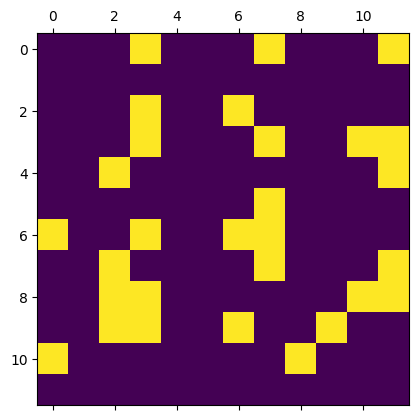

In [112]:
matshow(A_hs[0:12, 180:192], aspect = 'auto')
# A_hs_sub = A_hs[10:30, 424:444]
# M_hs_sub = M_hs[10:30, 424:444]

A_hs_sub = A_hs[0:12, 180:192]
M_hs_sub = M_hs[0:12, 180:192]

In [113]:
# Search for "densest" area of observed values in the data
# define density as the number of observed values over the area of the square.
# square area 15 x 15
from numpy.lib.stride_tricks import as_strided
max_unit = 0
global_max_density = 0
max_matrix = None
for j in [20]:
    sub_shape = (j, j)
    view_shape = tuple(np.subtract(A_hs_sub.shape, sub_shape) + 1) + sub_shape
    arr_view = as_strided(A_hs_sub, view_shape, A_hs_sub.strides * 2, writeable = False)
    arr_view = arr_view.reshape((-1,) + sub_shape)
    max_dense = 0
    ind_max_dense = 0
    for i in range(len(arr_view)):
        density = np.sum(arr_view[i]) / (j * j)
        if density > max_dense:
            max_dense = density
            ind_max_dense = i

    if max_dense > global_max_density:
        max_matrix = arr_view[ind_max_dense]
        global_max_density = max_dense
        max_unit = j
        
    print(max_dense)
    print(ind_max_dense)

ValueError: negative dimensions are not allowed

In [ ]:
print(max_unit)
print(global_max_density)
print(max_matrix)

One of the largest/most dense regions in the dataset is `A_hs_sub` as described above. We use this data to compare user-user and item-item approaches in "overlapping" regions. These are regions in which there is an L-shaped pattern of observed data. At the corner of this L, there is a set of values that could benefit from imputation using either user information along subset of the L or item information along the opposing subset. We simulate this scenario using a dense region of the matrix as a proof of concept.

In [ ]:
# the lower right corner will be the test set (9x9)
tst_x_beg = len(A_hs_sub[0]) - 5 # cols
tst_x_end = len(A_hs_sub[0])
tst_y_beg = len(A_hs_sub) - 5 # rows
tst_y_end = len(A_hs_sub)

test_set_A = A_hs_sub[tst_y_beg : tst_y_end, tst_x_beg : tst_x_end]
test_set_M = M_hs_sub[tst_y_beg : tst_y_end, tst_x_beg : tst_x_end]
print(test_set_A)
#print(test_set_M)

To set up our process, we take the segment immediately to the left of the test segment and use cross validation to tune $\eta$ with the item-item NN variations. Then, we use the tuned $\eta$ to estimate values in the test set using only the block to the left and the test square. We repeat the process for the segment immediately above the test square and with the user-user variation. Finally, we compare test errors between the two segments.

In [ ]:
# item-item with "bottom" sub-chunk

# mask all other indices to cross-validate on just the sub-chunk
A_subc_b = A_hs_sub.copy()
A_subc_b[:,: tst_x_beg] = 0
A_subc_b[tst_y_beg : tst_y_end, tst_x_beg : tst_x_end] = 0
# k = 5
# eta_range = np.arange(10, 1500, step = 10)
# #eta_range = [350.]

# min_error = float("inf")
# best_eta = 0
# for eta in eta_range:
#     error = cross_validate_nn(M_hs, A_subc_b, 5, eta, estimate_li_nn_inds, mse)
#     print("Error for eta " + str(eta) + ": " + str(error))
#     if error < min_error:
#         min_error = error
#         best_eta = eta
A_subc_b

## Kernel NN/MMD Implementation

We take the same data format as implemented in `transform_dnn` above. Unlike Li (2019), we do not wish to aggregate the measurements in each unit x time cell as a mean. Instead, we will use them to approximate the distribution from which they were drawn. Since we do not have the true distributions of any of the entries, we can validate our performance.


In [ ]:
# might need more clarification on how MMD works with empirical distributions, i.e. how to find
# order statistics or values to impute etc..

In [131]:
def rbf_kernel(x, y):
    """
    Computes the rbf kernel matrix entry K_xy
    """
    # what to put here - in other implementaion of rbf, had bandwidth ranges
    sigma2 = 5
    return np.exp(-0.5*np.linalg.norm(x - y)**2 / (2 * sigma2))
    
def mmd_sqd(X_i, X_j, kern):
    """
    Return the MMD^2 distance between rows with n measurements in each cell
    X_i and X_j
    
    Parameters:
    ----------
    X_i : (T - 1) x n matrix
    X_J : a T - 1) x n matrix
    kern : kernel function
    """
    sum_h = 0
    n = len(X_i)
    for l, l_p in itertools.combinations(range(n), r=2):
        if l != l_p:
            x = X_i[l]
            x_p = X_i[l_p]
            y = X_j[l]
            y_p = X_j[l_p]
            sum_h += kern(x, x_p) + kern(y, y_p) - kern(x, y_p) - kern(x_p, y)
    
    return (1 / (n * (n - 1)) * (sum_h))
        
    
def dissim_mmd(X, A, i, j, kern):
    """
    Measures the dissimilarity between rows i and j using maximum mean discrepancies (MMD)
    
    Parameters: 
    ----------
    X : N x (T - 1) x n array
    A : N x (T - 1) matrix that denotes which entries of X are observed
    i : indice of a row in X
    j : indice of row in X
    kern : kernel function
    """
    full_mask = A[i] * A[j]
    overlap = np.sum(full_mask)
    if not overlap:
        return float("inf") 
    mmd_dissims = mmd_sqd(X[i], X[j], kern) 
    return np.sum(mmd_dissims * full_mask) / overlap
            
def mmd_barycenter(X, A, i, t, eta):
    """
    Compute the squared MMD barycenter
    """
    
    #concatenated = chain(range(50), range(51, 100))
    # idk at the moment
    #for i in concatenated
    # unsure about u statistic in MMD code
    dissims = dissim_mmd(X, A, )
    neighborhood = 1

In [141]:
mmd_sqd(np.array([1, 2, 3]), np.array([2, 1, 1]), rbf_kernel)

-0.016256858499761974

## Optimal Transport/Wasserstein Implementation

In [ ]:
# Wassertein distance -> the barycenter is described by its order statistics, which we use as
# our estimates for imputation? it seems like it becomes the mean of the (sorted)
# neighbors at the measurement level in the empirical case

In [ ]:
# is the empirical barycenter just the order statistics on the distribution, which are in turn the average of the measurements across columns?
def wasserstein2_dist(Y, A, u, i):
    """
    Return Wasserstein_2^2 distance between row u and row i of 
    observed entries in array Y

    Parameters: 
    ----------
    Y : (M + 1) x (N + 1) x n array
    A : (M + 1) x (N + 1) masking array that denotes which entries of X are observed
    u : indice of row in Y
    i : indice of row in Y
    """